# FBphophet
- [Prophet] (https://facebook.github.io/prophet/) es un software de código abierto lanzado por el equipo de Core Data Science de Facebook.
- Prophet es un procedimiento para pronosticar datos de series de tiempo basado en un modelo aditivo / multiplicativo donde las tendencias no lineales se ajustan a la estacionalidad anual, semanal y diaria, más los efectos de vacaciones.
- Funciona mejor con series de tiempo que tienen fuertes efectos estacionales y varias temporadas de datos históricos.
- Prophet es robusto ante los datos faltantes y los cambios en la tendencia, y generalmente maneja bien los valores atípicos.
- El paquete Prophet proporciona parámetros intuitivos que son fáciles de ajustar.

## Entorno

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Dataset

In [28]:
import os

ruta = os.getcwd()
ruta_csv = os.path.join(ruta, 'demanda1.csv')
df = pd.read_csv(ruta_csv)
df.head()

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
0,2010-01-01,35.00,7.00000,0,1,primavera
1,2010-02-01,28.00,5.60000,0,2,invierno
2,2010-03-01,30.80,6.32800,0,3,invierno
3,2010-04-01,27.72,5.69520,0,4,invierno
4,2010-05-01,41.58,5.97996,0,5,otoño


## Preparacion de Datos

In [29]:
df = df.rename(columns={'demanda': 'y', 'fecha':'ds'}) # <-- Prophet requiere que los nombres de las variables en la serie de tiempo sean: y = m3; ds =fehca
df['ds'] = pd.to_datetime(df['ds'])

## Separación
No aplica en FbProphet

## Algoritmo Multivariable


### Entrenamiento

In [30]:
from prophet import Prophet

model = Prophet(yearly_seasonality=True, # <-- # Configuramos Prophet con estacionalidad anual (ideal para datos mensuales o estacionales)
                seasonality_mode='multiplicative', # <-- modo multiplicativo si la tendencia o estacionalidad crece proporcionalmente al nivel de la serie
                scaling="minmax",
                # changepoint_prior_scale=0.5,  # Valor más alto = mayor flexibilidad ante cambios de tendencia
                # growth = 'logistic'
                )

# model.add_country_holidays(country_name='PE') # <-- Si deseas agregar feriados del pais

model.add_regressor('aforo_mensual') # <-- Si deseas agregar variables exógenas (como temperatura o humedad), puedes usarlas con:
model.add_regressor('anomalia') # <-- Si deseas agregar variables exógenas (como temperatura o humedad), puedes usarlas con:

model.fit(df)

20:48:31 - cmdstanpy - INFO - Chain [1] start processing
20:48:32 - cmdstanpy - INFO - Chain [1] done processing


#### Predicciones

In [31]:
# Creamos el dataframe futuro para 12 meses más ('MS' = Inicio de mes)
periods_to_predict = 12 
future = model.make_future_dataframe(periods=periods_to_predict, freq='MS')

# 1. Unimos los valores históricos reales de los regresores con las fechas de Prophet
future = pd.merge(future, df[['ds', 'aforo_mensual', 'anomalia']], on='ds', how='left')

# 2. Asignamos los valores proyectados para los 12 meses futuros 
# (Reemplaza los corchetes con tus listas de 12 valores estimados para el futuro)
last12 = df['aforo_mensual'].iloc[-12:].values
prev12 = df['aforo_mensual'].iloc[-24:-12].values
future.loc[future['aforo_mensual'].isna(), 'aforo_mensual'] = last12 + (last12 - prev12)
future['anomalia'] = future['anomalia'].fillna(0)

# Realizamos la predicción con el modelo
forecast = model.predict(future)

# Visualizamos los últimos 12 meses pronosticados
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(12)

,ds,yhat,yhat_lower,yhat_upper
202,2026-11-01,112.714348,106.402659,119.062933
203,2026-12-01,273.244929,267.158179,279.462801
204,2027-01-01,57.190197,51.092743,63.031268
205,2027-02-01,35.339997,29.316505,41.555635
206,2027-03-01,47.315064,40.860921,53.188242
207,2027-04-01,36.122411,30.303433,42.326459
208,2027-05-01,73.392824,67.100540,79.235051
209,2027-06-01,95.335399,89.256423,101.667155
210,2027-07-01,65.507308,59.329372,71.973702
211,2027-08-01,53.239787,46.718205,59.474723


#### Evaluación

##### Evaluación de Predicción (Opcional)

El R^2 no es confiable en series de tiempo por tres razones:
- Efecto tendencia: Un valor alto suele reflejar solo la tendencia o estacionalidad general, enmascarando errores en cambios o fluctuaciones finas.
- Autocorrelación: Viola el supuesto estadístico de que los errores son independientes entre sí.
- Enfoque retrospectivo: Mide el ajuste histórico de los datos y no la capacidad real de pronóstico a futuro.

In [37]:
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error, median_absolute_error)

def evaluate_forecast(y_true, y_pred):
    results = pd.DataFrame({
        'r2_score': [r2_score(y_true, y_pred)],
        'mean_absolute_error': [mean_absolute_error(y_true, y_pred)],
        'median_absolute_error': [median_absolute_error(y_true, y_pred)],
        'mse': [mean_squared_error(y_true, y_pred)],
        'rmse': [np.sqrt(mean_squared_error(y_true, y_pred))]
    })
    return results

In [38]:
# Extraemos las predicciones correspondientes únicamente al periodo de validación
# Alineamos por fecha para comparar exactamente los valores reales vs predichos
eval_forecast = df.merge(forecast[['ds', 'yhat']], on='ds', how='inner')
predictions_valid = eval_forecast['yhat'].values
actuals_valid = eval_forecast['y'].values

In [39]:
# Calcular métricas de error en validación
metrics_results = evaluate_forecast(actuals_valid, predictions_valid)
print("\n--- Métricas de Evaluación en Validación ---")
metrics_results


--- Métricas de Evaluación en Validación ---


,r2_score,mean_absolute_error,median_absolute_error,mse,rmse
0,0.501285,13.143894,8.671003,445.043552,21.096055


In [40]:
evaluate_forecast(actuals_valid[-12:], predictions_valid[-12:]) # Mide el error en los últimos 12 meses (ajuste in-sample)

,r2_score,mean_absolute_error,median_absolute_error,mse,rmse
0,0.552958,13.558956,7.902897,601.082279,24.516979


##### Grafica para la Validacion

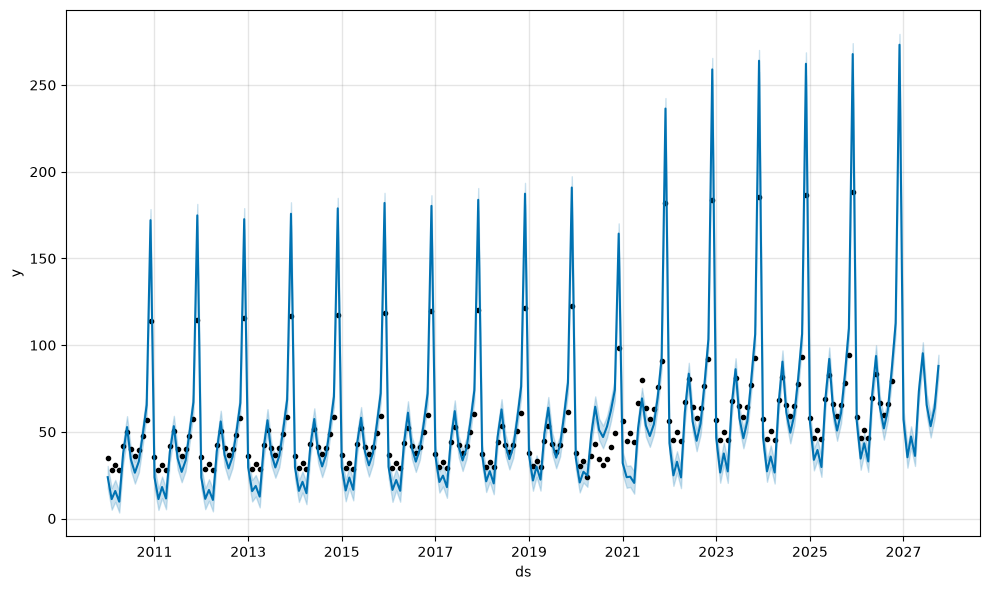

In [41]:
fig1 = model.plot(forecast)
# plt.axhline(y=0, color='red') # <-- Dibuja la linea roja si quieres poner un limite

##### Puntos de Cambio de Tendencia

Prophet coloca de forma automática potenciales puntos de cambio distribuidos en el primer 80% de las fechas históricas de tu serie temporal.

Selección por regularización: El algoritmo evalúa en cuáles de esos puntos ocurre un cambio de pendiente estadísticamente relevante según la penalización estándar (changepoint_prior_scale=0.05 por defecto) y marca los más importantes.

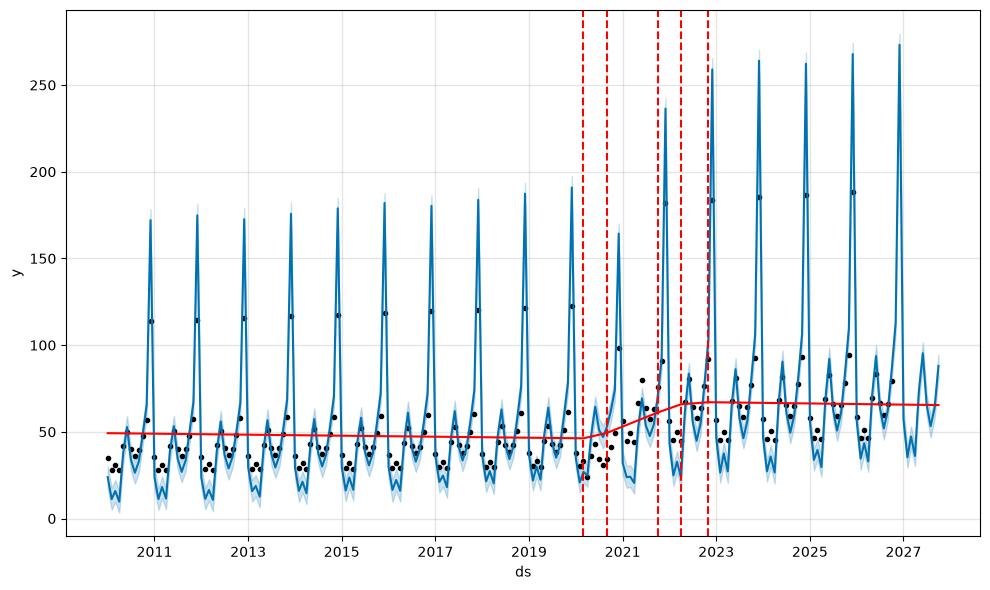

In [42]:
from prophet.plot import add_changepoints_to_plot
fig = model.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), model, forecast)

##### Gráfico de Punto de Cambio
En este ejemplo, no figura el punto de cambio

20:48:40 - cmdstanpy - INFO - Chain [1] start processing
20:48:40 - cmdstanpy - INFO - Chain [1] done processing


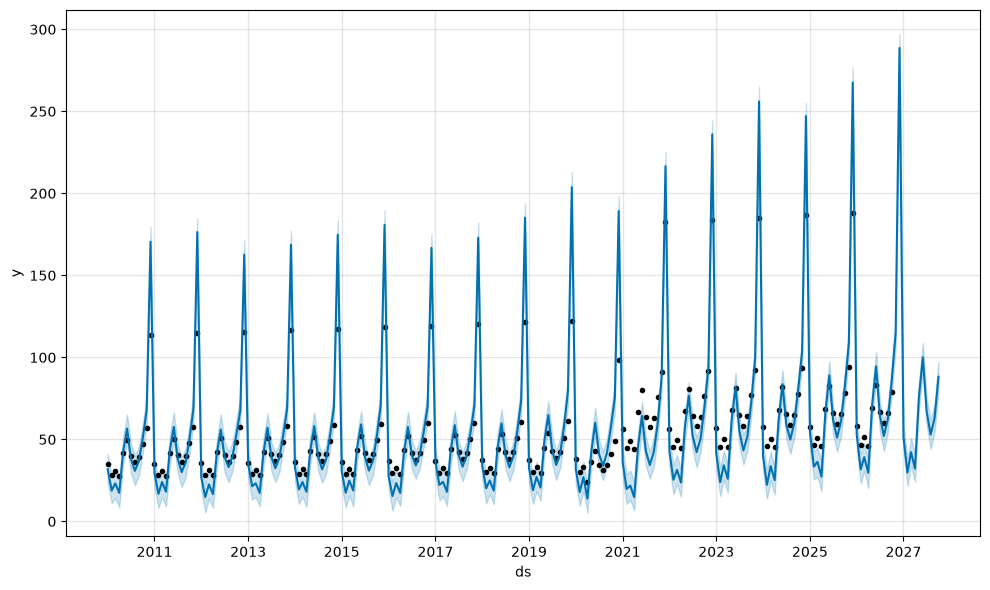

In [43]:
model_cp = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative', scaling="minmax",
                   changepoints=[df['ds'].iloc[len(df)//2].strftime('%Y-%m-%d')])
model_cp.add_regressor('aforo_mensual')
model_cp.add_regressor('anomalia')
forecast_cp = model_cp.fit(df).predict(future)
fig = model_cp.plot(forecast_cp)

##### Gráfica de Descomposición de Componentes

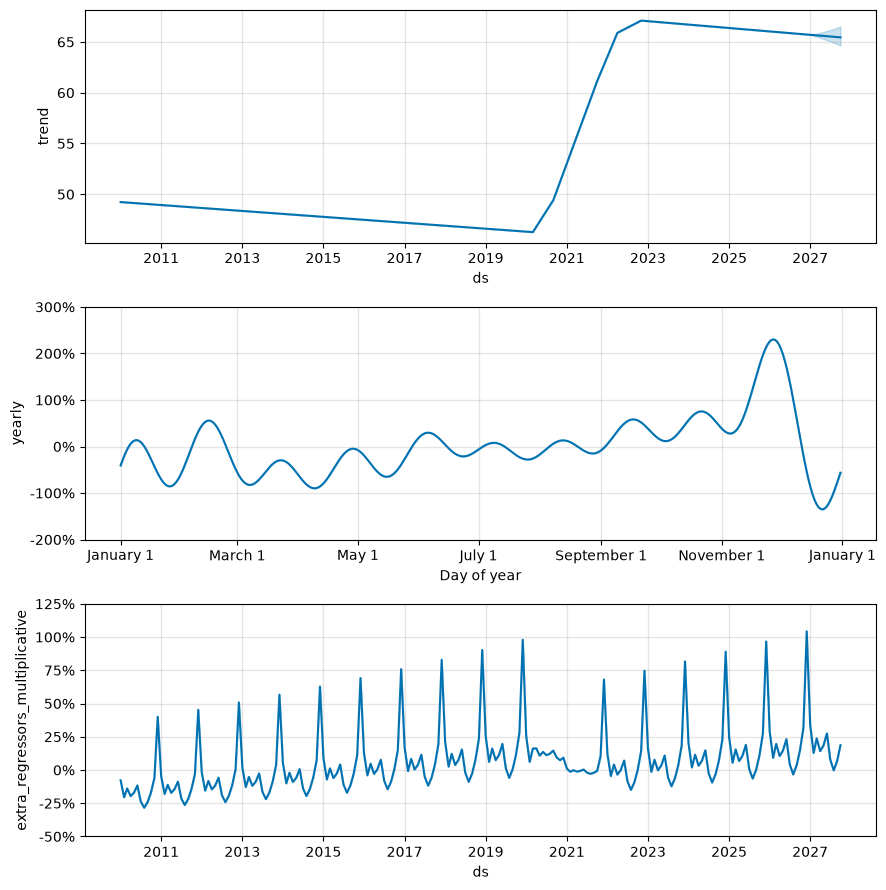

In [44]:
# Gráfica de componentes (Tendencia y Estacionalidad)
fig_components = model.plot_components(forecast)
plt.show()

In [ ]:
from prophet.utilities import regressor_coefficients
regressor_coefficients(model)

,regressor,regressor_mode,center,coef_lower,coef,coef_upper
0,aforo_mensual,multiplicative,7.84478,0.091318,0.091318,0.091318
1,anomalia,multiplicative,0.00000,0.605147,0.605147,0.605147


20:48:33 - cmdstanpy - INFO - Chain [1] start processing
20:48:33 - cmdstanpy - INFO - Chain [1] done processing


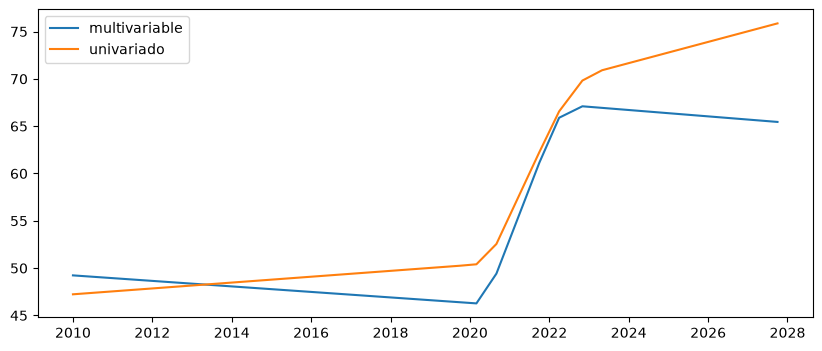

In [ ]:
m_uni = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative', scaling="minmax").fit(df)
fc_uni = m_uni.predict(m_uni.make_future_dataframe(periods=12, freq='MS'))

plt.figure(figsize=(10,4))
plt.plot(forecast['ds'], forecast['trend'], label='multivariable')
plt.plot(fc_uni['ds'], fc_uni['trend'], label='univariado')
plt.legend(); plt.show()

In [ ]:
forecast[['ds', 'trend', 'yearly', 'extra_regressors_multiplicative']].tail(36)

,ds,trend,yearly,extra_regressors_multiplicative
178,2024-11-01,66.428685,0.373815,0.228543
179,2024-12-01,66.401070,2.059710,0.889984
180,2025-01-01,66.372535,-0.407660,0.247441
181,2025-02-01,66.343999,-0.544508,0.054678
182,2025-03-01,66.318225,-0.558837,0.154915
183,2025-04-01,66.289690,-0.619617,0.067786
184,2025-05-01,66.262075,-0.077658,0.106994
185,2025-06-01,66.233539,0.200868,0.189331
186,2025-07-01,66.205925,-0.062893,0.008190
187,2025-08-01,66.177389,-0.169441,-0.064266


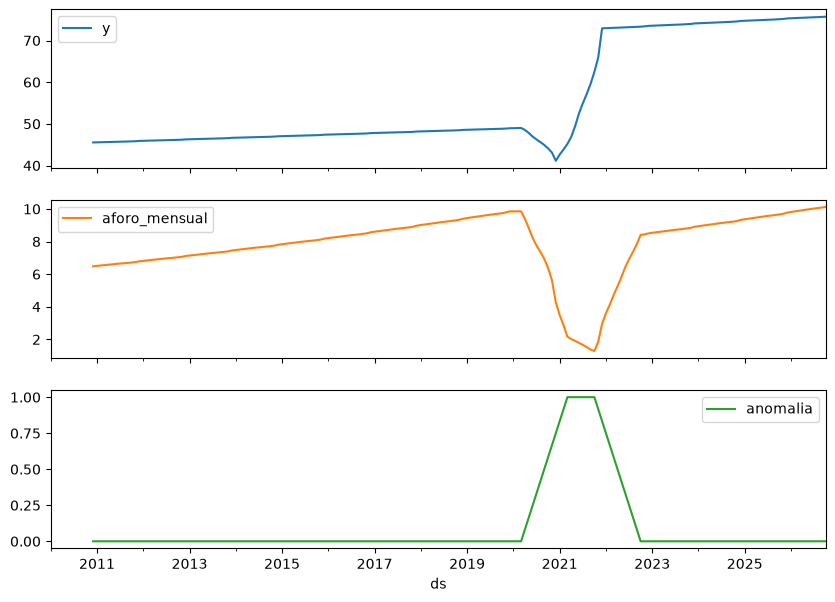

In [ ]:
df.set_index('ds')[['y', 'aforo_mensual', 'anomalia']].rolling(12).mean().plot(subplots=True, figsize=(10,7))
plt.show()

In [ ]:
df[['y', 'aforo_mensual', 'anomalia']].corr()

,y,aforo_mensual,anomalia
y,1.000000,0.652893,-0.035719
aforo_mensual,0.652893,1.000000,-0.616946
anomalia,-0.035719,-0.616946,1.000000


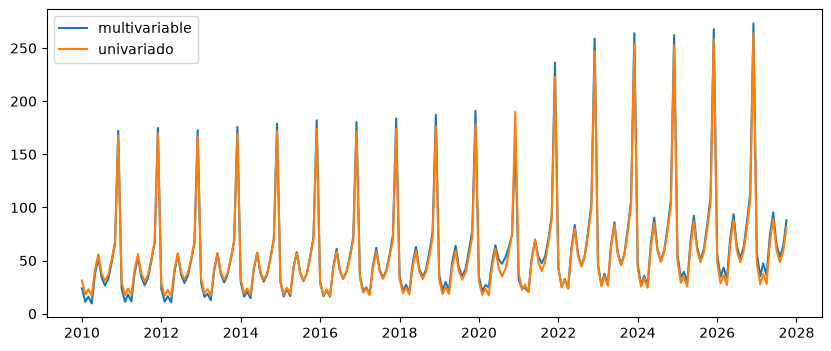

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(forecast['ds'], forecast['yhat'], label='multivariable')
plt.plot(fc_uni['ds'], fc_uni['yhat'], label='univariado')
plt.legend(); plt.show()

In [52]:
df_cv_multi = cross_validation(model, cutoffs=cutoffs, horizon='365 days')
df_cv_uni = cross_validation(m_uni, cutoffs=cutoffs, horizon='365 days')

print(performance_metrics(df_cv_multi, rolling_window=1)[['rmse','mape']])
print(performance_metrics(df_cv_uni, rolling_window=1)[['rmse','mape']])

  0%|          | 0/28 [00:00<?, ?it/s]21:03:21 - cmdstanpy - INFO - Chain [1] start processing
21:03:44 - cmdstanpy - INFO - Chain [1] done processing
  4%|▎         | 1/28 [00:23<10:26, 23.20s/it]21:03:44 - cmdstanpy - INFO - Chain [1] start processing
21:04:11 - cmdstanpy - INFO - Chain [1] done processing
  7%|▋         | 2/28 [00:49<10:52, 25.10s/it]21:04:11 - cmdstanpy - INFO - Chain [1] start processing
21:04:50 - cmdstanpy - INFO - Chain [1] done processing
 11%|█         | 3/28 [01:28<13:06, 31.45s/it]21:04:50 - cmdstanpy - INFO - Chain [1] start processing
21:05:31 - cmdstanpy - INFO - Chain [1] done processing
 14%|█▍        | 4/28 [02:09<14:08, 35.36s/it]21:05:31 - cmdstanpy - INFO - Chain [1] start processing
21:05:32 - cmdstanpy - INFO - Chain [1] done processing
 18%|█▊        | 5/28 [02:10<08:45, 22.84s/it]21:05:32 - cmdstanpy - INFO - Chain [1] start processing
21:05:32 - cmdstanpy - INFO - Chain [1] done processing
 21%|██▏       | 6/28 [02:11<05:36, 15.31s/it]21:05:32

        rmse      mape
0  11.470618  0.094306
        rmse      mape
0  10.392712  0.084015


### Validación Cruzada

In [45]:
from prophet.diagnostics import cross_validation

# Equivalencias aproximadas en días:
# 1 mes = 30 días (aprox)
# 2 años = 730 días
# 6 meses = 180 días
# 12 meses = 365 días

df_cv = cross_validation(
    model,                  # Usando tu variable 'model'
    initial='730 days',     # Ej: 2 años de entrenamiento inicial
    period='180 days',      # Ej: Realizar un corte cada 6 meses ('6M')
    horizon='365 days'      # Ej: Pronosticar los siguientes 12 meses ('12M')
)

  0%|          | 0/28 [00:00<?, ?it/s]20:48:42 - cmdstanpy - INFO - Chain [1] start processing
20:49:08 - cmdstanpy - INFO - Chain [1] done processing
  4%|▎         | 1/28 [00:26<11:53, 26.42s/it]20:49:08 - cmdstanpy - INFO - Chain [1] start processing
20:49:46 - cmdstanpy - INFO - Chain [1] done processing
  7%|▋         | 2/28 [01:04<14:29, 33.43s/it]20:49:46 - cmdstanpy - INFO - Chain [1] start processing
20:50:26 - cmdstanpy - INFO - Chain [1] done processing
 11%|█         | 3/28 [01:44<15:06, 36.27s/it]20:50:26 - cmdstanpy - INFO - Chain [1] start processing
20:50:26 - cmdstanpy - INFO - Chain [1] done processing
 14%|█▍        | 4/28 [01:45<08:52, 22.21s/it]20:50:27 - cmdstanpy - INFO - Chain [1] start processing
20:50:27 - cmdstanpy - INFO - Chain [1] done processing
 18%|█▊        | 5/28 [01:46<05:35, 14.59s/it]20:50:28 - cmdstanpy - INFO - Chain [1] start processing
20:50:28 - cmdstanpy - INFO - Chain [1] done processing
 21%|██▏       | 6/28 [01:47<03:38,  9.94s/it]20:50:29

In [46]:
df_cv.head()


,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2012-07-01,40.251697,40.210326,40.294706,40.561109,2012-06-11
1,2012-08-01,36.088143,35.967943,36.218105,36.504998,2012-06-11
2,2012-09-01,39.690209,39.421805,39.971534,40.155498,2012-06-11
3,2012-10-01,47.554760,47.054910,48.083871,48.186597,2012-06-11
4,2012-11-01,56.883865,56.045221,57.783485,57.823917,2012-06-11


In [47]:
from prophet.diagnostics import performance_metrics
df_p = performance_metrics(df_cv)
df_p.head()

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,101.670321,10.083170,5.000781,0.066485,0.004213,0.072605,0.181818
1,39 days,101.384072,10.068966,4.911028,0.063990,0.003296,0.070216,0.181818
2,40 days,224.447907,14.981586,6.839085,0.074561,0.004213,0.083032,0.181818
3,41 days,224.391143,14.979691,6.812861,0.074044,0.004213,0.082526,0.181818
4,42 days,225.646237,15.021526,6.982085,0.075908,0.004213,0.084305,0.181818


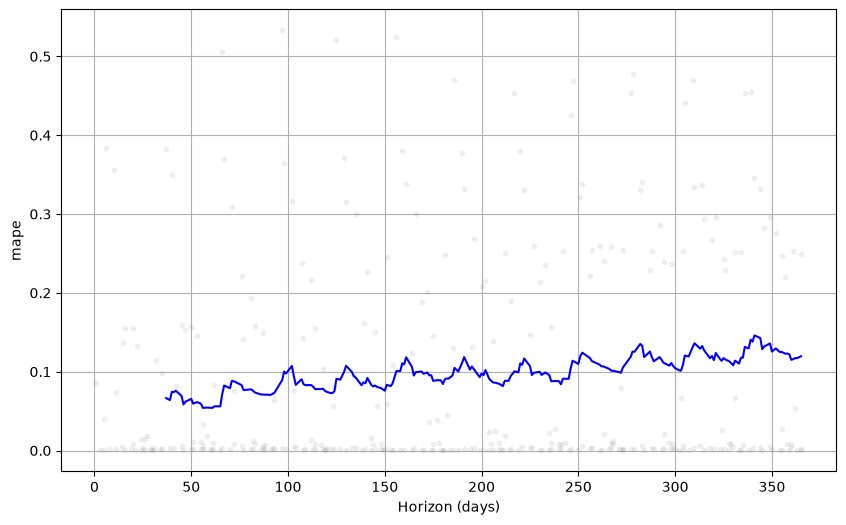

In [48]:
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='mape')

### Hiperparametros

In [49]:
initial_date = df['ds'].min() + pd.Timedelta(days=730)
end_date = df['ds'].max() - pd.Timedelta(days=365)
cutoffs = pd.date_range(start=initial_date, end=end_date, freq='180D')

In [ ]:
import itertools

# Definir la cuadrícula de parámetros a evaluar
param_grid = {  
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'seasonality_prior_scale': [0.1, 1.0, 10.0],
}

# Generar todas las combinaciones posibles de parámetros
all_params = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
rmses = []  # Almacenar los RMSEs para cada combinación

# Bucle para probar cada combinación mediante validación cruzada
for params in all_params:
    m = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative', scaling="minmax", **params).fit(df)
    df_cv_i = cross_validation(
        m,
        cutoffs=cutoffs,
        horizon='365 days',
        parallel="processes"
    )
    df_p = performance_metrics(df_cv_i, rolling_window=1)
    rmses.append(df_p['rmse'].values[0])

# Estructurar los resultados y encontrar los mejores hiperparámetros
tuning_results = pd.DataFrame(all_params)
tuning_results['rmse'] = rmses
print("--- Resultados de la Optimización ---")
print(tuning_results)

# Limpiar posibles nulos, extraer el mejor set y entrenar el modelo final
tuning_results = tuning_results.dropna(subset=['rmse'])
best_params = tuning_results.loc[tuning_results['rmse'].idxmin()].drop('rmse').to_dict()

print("\nMejores parámetros encontrados:", best_params)

# Entrenar el modelo definitivo con la mejor configuración
model_final = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative', **best_params).fit(df)

21:57:14 - cmdstanpy - INFO - Chain [1] start processing
21:57:18 - cmdstanpy - INFO - Chain [1] done processing
21:58:34 - cmdstanpy - INFO - Chain [1] start processing
21:58:35 - cmdstanpy - INFO - Chain [1] done processing
21:59:27 - cmdstanpy - INFO - Chain [1] start processing
21:59:27 - cmdstanpy - INFO - Chain [1] done processing
22:00:22 - cmdstanpy - INFO - Chain [1] start processing
22:00:22 - cmdstanpy - INFO - Chain [1] done processing
22:01:17 - cmdstanpy - INFO - Chain [1] start processing
22:01:17 - cmdstanpy - INFO - Chain [1] done processing
